# Task 2 - Real Estate Housing Price Prediction (Ridge & Lasso)

Goal: predict the median house value of a California block group.

This is supervised regression. Every row in `housing.csv` already has the median value. I will train on most of the rows, then score the model on rows it has not seen. The prediction is a dollar amount, so the scores are RMSE, MAE, and R².

- Features: location, age of the houses, rooms, bedrooms, population, households, median income, and how close the block is to the ocean
- Target: `median_house_value`

One row is one block group, not one house. The target is the median value of the houses in that block.

By the end of this notebook I will have:

1. Loaded the data and checked the missing values.
2. Imputed `total_bedrooms` and plotted correlation heatmaps.
3. Built ratio features and centered interaction features.
4. Checked multicollinearity, and encoded the coast so the ocean columns do not copy the intercept.
5. Scaled the continuous columns, then fit OLS, Ridge, and Lasso. Ridge and Lasso search over `alpha` with `GridSearchCV`.
6. Compared RMSE, MAE, and R².
7. Plotted predicted against actual values and the residual curves.


## Plan

1. Know the data - load `housing.csv` and check the columns, the missing bedroom counts, and the ocean categories.
2. See what moves with price - fill the missing bedrooms for a correlation heatmap.
3. Split 80/20, then impute from the training rows only.
4. Engineer features - rooms per household, bedrooms per room, people per household, and two centered interactions with income.
5. Check multicollinearity - variance inflation factors for the overlapping count columns.
6. Scale the continuous columns and one-hot encode `ocean_proximity`.
7. Fit three models - Ordinary Least Squares, Ridge, and Lasso. Grid search picks the Ridge and Lasso penalty.
8. Compare RMSE, MAE, and R², then plot predicted against actual and the residual distributions.


---

## Section 1 - Know the data

I want a clear look at the table before I impute anything or train a model.

1. Load `housing.csv`.
2. Look at a few rows.
3. Check the types, the missing values, and the range of each column.
4. Count the blocks in each ocean category.

One row is one block group. Later the model takes the location, the counts, the income, and the coast, and predicts the median house value.


In [1]:
import pandas as pd

# loading the dataset
df = pd.read_csv("housing.csv")

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")


Shape: 20640 rows, 10 columns


### A few rows

The numbers are measurements for a block group. `ocean_proximity` is text. `median_house_value` is the label I want to predict, in dollars.


In [2]:
# Displaying the first five rows of the loaded dataset
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Types, missing values, and the coast


In [3]:
# Checking the datatypes of the variables
print(df.dtypes)
print()

# Checking the missing values
print(df.isnull().sum())
print()

# How many blocks in each ocean category
print(df["ocean_proximity"].value_counts())
print()

cap = df["median_house_value"].max()
cap_rows = int((df["median_house_value"] == cap).sum())
print(f"Highest median house value: {cap:,.0f}")
print(f"Blocks stored at that exact value: {cap_rows}")


longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Highest median house value: 500,001
Blocks stored at that exact value: 965


In [4]:
# Summary of each numeric column
df.describe().round(2)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


### What the table shows

`total_bedrooms` is the only column with missing values: 207 blocks. The other columns are complete.

`ocean_proximity` is text. Most blocks are `<1H OCEAN` or `INLAND`.

The highest `median_house_value` is 500001.

---

## Section 2 - Impute the missing bedrooms and plot the correlations

A correlation heatmap needs a number in every cell. I fill the 207 missing bedroom counts with the median bedroom count so the picture includes every block.

This fill is for the heatmap. In Section 3 the model learns the median from the training rows only, then applies that median to the test rows.


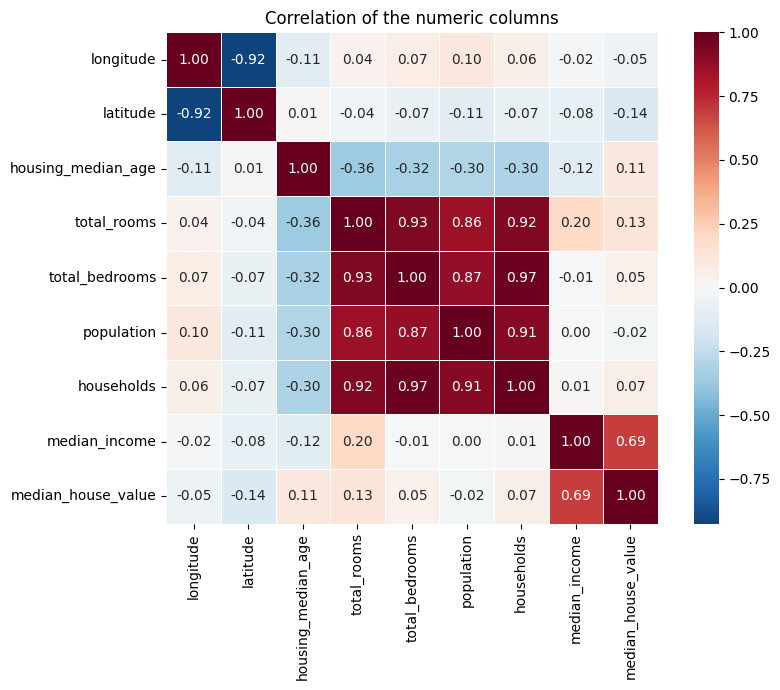

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

picture = df.copy()
picture["total_bedrooms"] = picture["total_bedrooms"].fillna(picture["total_bedrooms"].median())

numeric_columns = picture.select_dtypes(include="number").columns
correlation = picture[numeric_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.4,
)
plt.title("Correlation of the numeric columns")
plt.tight_layout()
plt.show()


### What the heatmap says

`median_income` is the strongest linear link with `median_house_value`. That cell is about 0.69.

`total_rooms`, `total_bedrooms`, `population`, and `households` are strongly tied to each other. A block with more households also has more rooms, more bedrooms, and more people. Those four columns describe the same blocks in different units. That overlap is the multicollinearity I measure in Section 5.

Longitude and latitude move together as well, because the California coast runs diagonally.


---

## Section 3 - Split, then impute from the training rows

I hold out 20% of the blocks before I fit anything. The bedroom median, the feature means, the population cap, and the scaler all learn from the training rows. The test rows stay unseen until the scores in Section 8.


In [6]:
from sklearn.model_selection import train_test_split

train_raw, test_raw = train_test_split(df, test_size=0.2, random_state=42)

print(f"Training rows: {len(train_raw)}")
print(f"Test rows: {len(test_raw)}")
print(f"Missing bedrooms in the training rows: {int(train_raw['total_bedrooms'].isna().sum())}")
print(f"Missing bedrooms in the test rows: {int(test_raw['total_bedrooms'].isna().sum())}")


Training rows: 16512
Test rows: 4128
Missing bedrooms in the training rows: 0
Missing bedrooms in the test rows: 207


This split put all 207 missing bedroom counts into the test rows. The training rows are complete. The fill value is still the training median, 437, learned from the training blocks and then written into the test blocks that need it.


---

## Section 4 - Engineer ratio and interaction features

Raw room and population counts grow with the size of the block. A ratio puts those counts on a per-household scale.

- `rooms_per_household` = `total_rooms` / `households`
- `bedrooms_per_room` = `total_bedrooms` / `total_rooms`
- `population_per_household` = `population` / `households`

A few blocks report a huge number of people per household. One value is large enough to pull a straight line toward it. I cap `population_per_household` at the 99th percentile of the training rows.

Two interaction features let income change its slope.

- `income_x_rooms` is high when a high-income block also has more rooms per household.
- `income_x_age` is high when a high-income block also has older houses.

I subtract the training mean from each piece before multiplying. A raw product of income and rooms tracks income itself, because a large income makes the product large even when the room ratio is ordinary. Centering leaves the extra joint effect.


In [7]:
bedroom_median = float(train_raw["total_bedrooms"].median())

filled_train = train_raw.copy()
filled_train["total_bedrooms"] = filled_train["total_bedrooms"].fillna(bedroom_median)
rooms_per_household = filled_train["total_rooms"] / filled_train["households"]
people_per_household = filled_train["population"] / filled_train["households"]

income_mean = float(filled_train["median_income"].mean())
rooms_mean = float(rooms_per_household.mean())
age_mean = float(filled_train["housing_median_age"].mean())
pop_cap = float(people_per_household.quantile(0.99))

print(f"Training median of total_bedrooms: {bedroom_median:.0f}")
print(f"Largest people-per-household value in training: {people_per_household.max():.1f}")
print(f"Cap at the training 99th percentile: {pop_cap:.2f}")


def add_features(frame):
    built = frame.copy()
    built["total_bedrooms"] = built["total_bedrooms"].fillna(bedroom_median)
    built["rooms_per_household"] = built["total_rooms"] / built["households"]
    built["bedrooms_per_room"] = built["total_bedrooms"] / built["total_rooms"]
    people = built["population"] / built["households"]
    built["population_per_household"] = people.clip(upper=pop_cap)
    built["income_x_rooms"] = (built["median_income"] - income_mean) * (
        built["rooms_per_household"] - rooms_mean
    )
    built["income_x_age"] = (built["median_income"] - income_mean) * (
        built["housing_median_age"] - age_mean
    )
    return built


train = add_features(train_raw)
test = add_features(test_raw)

engineered_columns = [
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_x_rooms",
    "income_x_age",
]
train[engineered_columns].head()


Training median of total_bedrooms: 437
Largest people-per-household value in training: 1243.3
Cap at the training 99th percentile: 5.41


,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms,income_x_age
14196,5.017657,0.200576,3.691814,0.259381,-2.727933
8267,4.473545,0.232703,1.738095,0.065639,-1.391821
17445,5.645833,0.174486,2.723214,0.058029,-6.780708
14265,4.002817,0.258269,3.994366,2.776391,-14.327023
2271,6.268421,0.180940,2.300000,-0.272080,-4.699676


In [8]:
raw_product = train["median_income"] * train["rooms_per_household"]
print(
    "Correlation of the raw income x rooms product with income:",
    round(raw_product.corr(train["median_income"]), 3),
)
print(
    "Correlation of the centered interaction with income:",
    round(train["income_x_rooms"].corr(train["median_income"]), 3),
)


Correlation of the raw income x rooms product with income: 0.889
Correlation of the centered interaction with income: 0.41


### The raw product and the centered product

On the training rows, the raw product of income and rooms per household has a correlation of about 0.89 with income. The centered interaction drops that correlation to about 0.41. The model uses the centered interaction, so the new column carries the joint effect on top of income and on top of the room ratio.


---

## Section 5 - Check multicollinearity

Multicollinearity means one feature is close to a combination of the others. A linear model can still predict. The individual weights get harder to read, because two overlapping columns can trade weight back and forth.

The variance inflation factor (VIF) measures that overlap. A VIF of 1 means the column is separate from the others. I treat a VIF above 10 as a column that the other columns already explain.

The heatmap under the table is the four count columns on their own.


In [9]:
import numpy as np
from sklearn.linear_model import LinearRegression

numeric_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_x_rooms",
    "income_x_age",
]


def variance_inflation(frame):
    rows = []
    for column in frame.columns:
        target = frame[column]
        predictors = frame.drop(columns=column)
        r2 = LinearRegression().fit(predictors, target).score(predictors, target)
        vif = np.inf if r2 >= 1 else 1 / (1 - r2)
        rows.append({"feature": column, "VIF": vif})
    table = pd.DataFrame(rows).sort_values("VIF", ascending=False)
    return table.reset_index(drop=True)


vif_table = variance_inflation(train[numeric_features])
vif_table.round(2)


,feature,VIF
0,households,52.14
1,total_bedrooms,50.83
2,total_rooms,19.71
3,population,13.28
4,latitude,9.60
5,longitude,9.23
6,median_income,3.00
7,bedrooms_per_room,2.93
8,population_per_household,2.33
9,rooms_per_household,2.11


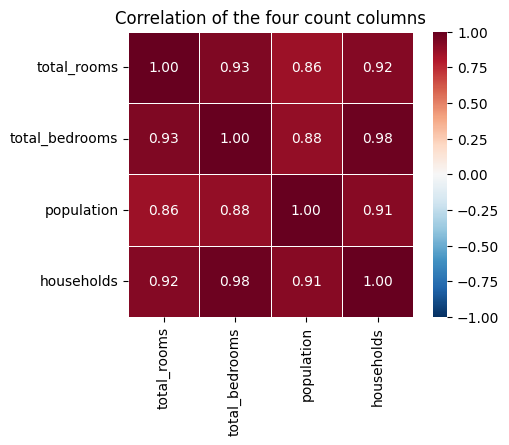

In [10]:
count_columns = ["total_rooms", "total_bedrooms", "population", "households"]

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    train[count_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.4,
)
plt.title("Correlation of the four count columns")
plt.tight_layout()
plt.show()


### How I handle it

Households and total bedrooms have a VIF near 50. Total rooms is near 20, and population is near 13. All four are above the line of 10, and the heatmap shows why: each pair is correlated at about 0.86 or higher. Latitude and longitude sit just under 10. I keep both coordinates, because placing a block on the map takes both.

I keep the four counts too. The ratios say how the rooms are shared. The counts still say how big the block is. Ridge and Lasso are built for this overlap: they keep both pieces and shrink a weight when the columns carry the same signal.

Two other overlaps are already removed.

- The interactions are centered, so they are a joint effect on top of income.
- The ocean encoder in the next section drops one category. Five ocean columns plus an intercept would add up to a column of ones. The dropped category is `<1H OCEAN`. Every other ocean coefficient is the difference versus that coast.


---

## Section 6 - Standardize the continuous columns and encode the coast

`StandardScaler` subtracts the training mean and divides by the training standard deviation. Income is in tens of thousands of dollars and the coordinates are in degrees. Without scaling, the Ridge and Lasso penalty would treat those units as if they were the same size.

`ocean_proximity` stays text until `OneHotEncoder` turns it into 0/1 columns. The first category, `<1H OCEAN`, is the reference and is left out.

Each model gets its own copy of this preprocessor. Fitting Ridge must leave the Lasso scaler untouched.


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

original_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
]


def make_preprocessor(numeric_columns):
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_columns),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    sparse_output=False,
                    handle_unknown="ignore",
                ),
                ["ocean_proximity"],
            ),
        ]
    )


def column_names(preprocessor, numeric_columns):
    encoder = preprocessor.named_transformers_["cat"]
    ocean_names = list(encoder.get_feature_names_out(["ocean_proximity"]))
    return list(numeric_columns) + ocean_names


target = "median_house_value"
y_train = train[target]
y_test = test[target]
X_train = train[numeric_features + ["ocean_proximity"]]
X_test = test[numeric_features + ["ocean_proximity"]]

# Fit once here so I can check the scaled training rows
scale_check = make_preprocessor(numeric_features)
scaled_train = scale_check.fit_transform(X_train)
scaled_frame = pd.DataFrame(
    scaled_train,
    columns=column_names(scale_check, numeric_features),
)

scaled_summary = pd.DataFrame(
    {
        "mean": scaled_frame[numeric_features].mean(),
        "std": scaled_frame[numeric_features].std(ddof=0),
    }
)
scaled_summary.round(4)


,mean,std
longitude,0.0,1.0
latitude,0.0,1.0
housing_median_age,-0.0,1.0
total_rooms,0.0,1.0
total_bedrooms,-0.0,1.0
population,0.0,1.0
households,-0.0,1.0
median_income,-0.0,1.0
rooms_per_household,-0.0,1.0
bedrooms_per_room,-0.0,1.0


The continuous training columns now have mean 0 and standard deviation 1. The ocean columns stay 0/1, so a coefficient on those columns is a dollar difference versus `<1H OCEAN`. A coefficient on a continuous column is the dollar change for a one-standard-deviation move.


---

## Section 7 - Fit OLS, Ridge, and Lasso

All three models are straight lines. They use the same scaled columns and the same training rows.

- Ordinary least squares (OLS) picks the weights that minimize squared error. It has no penalty.
- Ridge adds an L2 penalty. Large weights cost `alpha` times the sum of squared weights. The weights shrink, and a weight is not forced to zero.
- Lasso adds an L1 penalty. Large weights cost `alpha` times the sum of absolute weights. A large enough `alpha` sets some weights to exactly zero.

`GridSearchCV` tries each alpha on five folds of the training rows and keeps the alpha with the lowest root mean squared error. The test rows are not part of this search. The alpha grid runs from 0.001 to 10,000 so the curve can show where a stronger penalty starts to hurt.


In [12]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

alphas = np.logspace(-3, 4, 15)

ols = Pipeline(
    [
        ("prep", make_preprocessor(numeric_features)),
        ("model", LinearRegression()),
    ]
)
ols.fit(X_train, y_train)

ridge_search = GridSearchCV(
    Pipeline(
        [
            ("prep", make_preprocessor(numeric_features)),
            ("model", Ridge(random_state=42)),
        ]
    ),
    param_grid={"model__alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
)
ridge_search.fit(X_train, y_train)

lasso_search = GridSearchCV(
    Pipeline(
        [
            ("prep", make_preprocessor(numeric_features)),
            ("model", Lasso(random_state=42, max_iter=20000)),
        ]
    ),
    param_grid={"model__alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
)
lasso_search.fit(X_train, y_train)

ridge = ridge_search.best_estimator_
lasso = lasso_search.best_estimator_

print(f"Ridge alpha: {ridge_search.best_params_['model__alpha']:.4g}")
print(f"Ridge cross-validated RMSE: {-ridge_search.best_score_:,.0f}")
print(f"Lasso alpha: {lasso_search.best_params_['model__alpha']:.4g}")
print(f"Lasso cross-validated RMSE: {-lasso_search.best_score_:,.0f}")


Ridge alpha: 1
Ridge cross-validated RMSE: 65,745
Lasso alpha: 3.162
Lasso cross-validated RMSE: 65,746


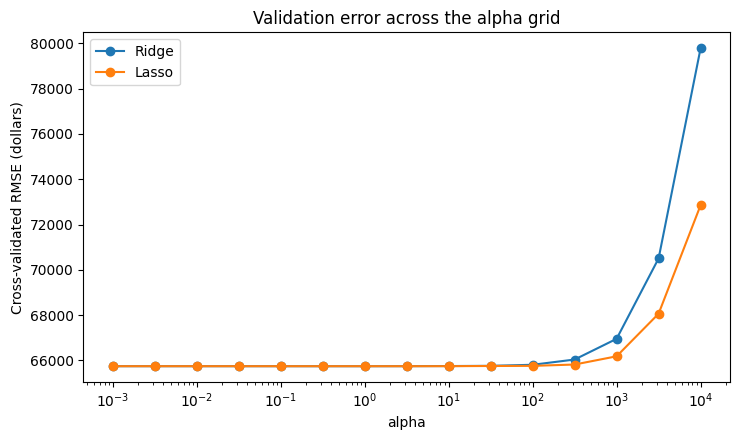

In [13]:
ridge_cv = -ridge_search.cv_results_["mean_test_score"]
lasso_cv = -lasso_search.cv_results_["mean_test_score"]

plt.figure(figsize=(7.5, 4.5))
plt.plot(alphas, ridge_cv, marker="o", label="Ridge")
plt.plot(alphas, lasso_cv, marker="o", label="Lasso")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Cross-validated RMSE (dollars)")
plt.title("Validation error across the alpha grid")
plt.legend()
plt.tight_layout()
plt.show()


### What the alpha curve says

The curve is flat while `alpha` is small, then it bends upward. A tiny penalty leaves the fit close to OLS. A penalty in the thousands pulls the weights too hard and the cross-validated error climbs.

Ridge picks `alpha` 1. Lasso picks `alpha` about 3.16. Both cross-validated RMSEs are about $65,745. Grid search stays on the flat part of the curve, where the penalty is light.


---

## Section 8 - Compare RMSE, MAE, and R²

The scores below are on the 4,128 test blocks.

- RMSE is the typical size of a miss, in dollars, with large misses counted more heavily.
- MAE is the average absolute miss, in dollars.
- R² is the share of the variation in median house value that the model accounts for. 1 would be a perfect fit.

The first row is an OLS model on the original columns, with this same split and the same bedroom impute, without the ratios or the interactions. The next three rows use the engineered columns.


In [14]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

baseline = Pipeline(
    [
        ("prep", make_preprocessor(original_features)),
        ("model", LinearRegression()),
    ]
)
baseline.fit(train[original_features + ["ocean_proximity"]], y_train)


def score_model(name, model, features):
    train_pred = model.predict(train[features + ["ocean_proximity"]])
    test_pred = model.predict(test[features + ["ocean_proximity"]])
    row = {
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train, train_pred),
        "Test RMSE": root_mean_squared_error(y_test, test_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Test R2": r2_score(y_test, test_pred),
    }
    return row, test_pred


rows = []
rows.append(score_model("OLS, original columns", baseline, original_features)[0])

ols_row, ols_pred = score_model("OLS", ols, numeric_features)
ridge_row, ridge_pred = score_model("Ridge", ridge, numeric_features)
lasso_row, lasso_pred = score_model("Lasso", lasso, numeric_features)
rows.extend([ols_row, ridge_row, lasso_row])

comparison = pd.DataFrame(rows)
comparison["Train RMSE"] = comparison["Train RMSE"].round(0)
comparison["Test RMSE"] = comparison["Test RMSE"].round(0)
comparison["Test MAE"] = comparison["Test MAE"].round(0)
comparison["Test R2"] = comparison["Test R2"].round(3)
comparison


,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,"OLS, original columns",68434.0,70059.0,50670.0,0.625
1,OLS,65635.0,71045.0,50069.0,0.615
2,Ridge,65636.0,71052.0,50076.0,0.615
3,Lasso,65635.0,71047.0,50071.0,0.615


### What the scores say

On the test blocks, OLS on the original columns has RMSE $70,059, MAE $50,670, and R² 0.625.

OLS on the engineered columns has RMSE $71,045, MAE $50,069, and R² 0.615. Ridge is RMSE $71,052 and MAE $50,076. Lasso is RMSE $71,047 and MAE $50,071. The three engineered models share R² 0.615.

The ratios and interactions pull the training error down, from about $68,434 to about $65,635. On the test rows the average absolute miss gets a little smaller, by about $600, and RMSE gets a little larger, by about $1,000. RMSE cares more about the big misses, so a handful of worse large errors can raise it while the typical block improves.

Ridge and Lasso stay with OLS on these scores. The alpha curve already showed that a light penalty is enough. The difference shows up in the weights, in the next table.


### Coefficients

These weights are from the three engineered models. A numeric coefficient is the dollar change for a one-standard-deviation move in that column. An ocean coefficient is the dollar difference versus `<1H OCEAN`.


In [15]:
names = column_names(ols.named_steps["prep"], numeric_features)
coefficients = pd.DataFrame(
    {
        "feature": names,
        "OLS": ols.named_steps["model"].coef_,
        "Ridge": ridge.named_steps["model"].coef_,
        "Lasso": lasso.named_steps["model"].coef_,
    }
)
coefficients = coefficients.sort_values("OLS", key=lambda column: column.abs(), ascending=False)
coefficients = coefficients.reset_index(drop=True)
coefficients.round(0)


,feature,OLS,Ridge,Lasso
0,ocean_proximity_ISLAND,115622.0,92493.0,102607.0
1,median_income,79498.0,79489.0,79494.0
2,latitude,-61670.0,-61601.0,-61596.0
3,longitude,-59213.0,-59142.0,-59130.0
4,ocean_proximity_INLAND,-34028.0,-34070.0,-34042.0
5,population_per_household,-23362.0,-23367.0,-23373.0
6,bedrooms_per_room,17009.0,17008.0,17008.0
7,housing_median_age,13407.0,13412.0,13405.0
8,ocean_proximity_NEAR BAY,-9048.0,-9037.0,-8973.0
9,total_bedrooms,5813.0,5833.0,5789.0


### What the coefficients say

Lasso sets the `households` weight to zero. That column has a VIF of 52, and the room, bedroom, and population counts already carry the same signal. The island weight is the other one that moves: OLS gives `ISLAND` about $115,600 versus `<1H OCEAN`, Ridge about $92,500, and Lasso about $102,600. Only four island blocks are in the training rows, so that weight is easy to overstate. One island block in the test set does not move RMSE.

`median_income` is the largest continuous weight, about $79,500 for a one-standard-deviation rise. An inland block is about $34,000 below an otherwise similar `<1H OCEAN` block.


---

## Section 9 - Predicted values and residual curves

A residual is the actual median value minus the prediction. Zero means the model hit that block. A positive residual means the model was low.

The black line on the first figure is a perfect prediction. A point above the line is a block the model priced too low. A point below the line is a block it priced too high.

The second figure is the distribution of those residuals. The curve on each histogram is the smoothed shape of the misses.


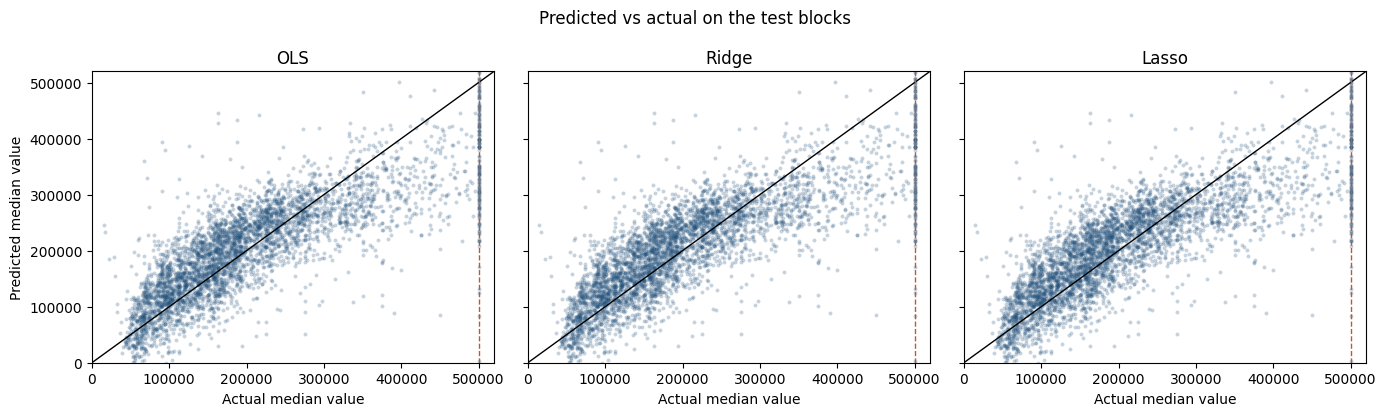

In [16]:
predictions = {
    "OLS": ols_pred,
    "Ridge": ridge_pred,
    "Lasso": lasso_pred,
}

figure, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
limit = 520000
for axis, (name, predicted) in zip(axes, predictions.items()):
    axis.scatter(y_test, predicted, s=8, alpha=0.25, color="#1f4e79", linewidths=0)
    axis.plot([0, limit], [0, limit], color="black", linewidth=1)
    axis.axvline(500001, color="#b85c38", linewidth=1, linestyle="--")
    axis.set_title(name)
    axis.set_xlabel("Actual median value")
    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)
axes[0].set_ylabel("Predicted median value")
figure.suptitle("Predicted vs actual on the test blocks")
figure.tight_layout()
plt.show()


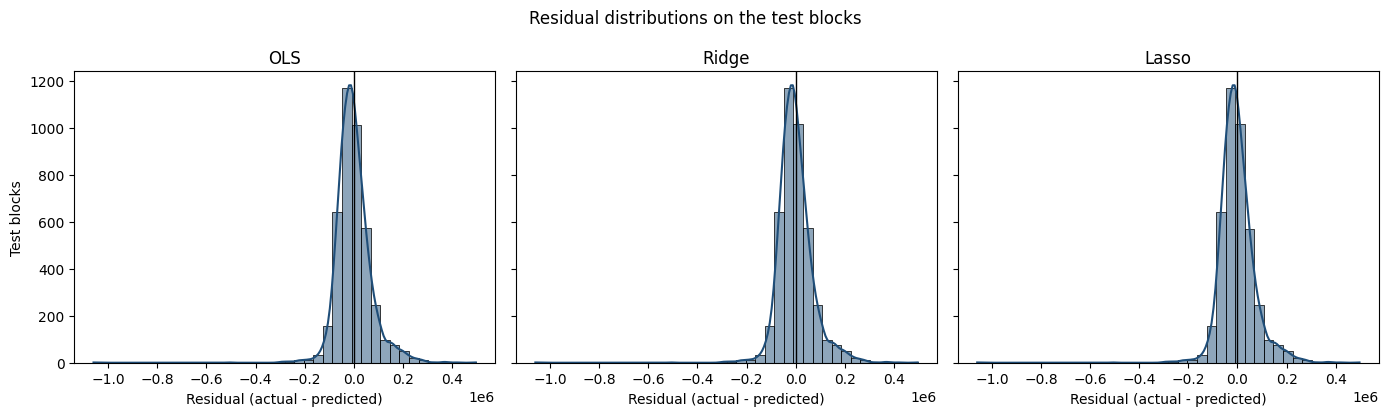

In [17]:
figure, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for axis, (name, predicted) in zip(axes, predictions.items()):
    residual = y_test.to_numpy() - predicted
    sns.histplot(residual, bins=40, kde=True, ax=axis, color="#1f4e79")
    axis.axvline(0, color="black", linewidth=1)
    axis.set_title(name)
    axis.set_xlabel("Residual (actual - predicted)")
axes[0].set_ylabel("Test blocks")
figure.suptitle("Residual distributions on the test blocks")
figure.tight_layout()
plt.show()


### What the plots say

The three predicted-versus-actual panels match, which fits the table above. The cloud follows the black line, and the scatter around that line is wide: the average absolute miss is about $50,000. The dashed line at $500,001 is the ceiling from Section 1. Those blocks form a vertical strip because every expensive block above the cap was stored as the same number.

The residual curves peak at zero. They stretch farther to the right than to the left. A large positive residual is a block the model priced too low. The capped blocks sit in that right tail, because a stored value of $500,001 often lands above the prediction.
